# 10_01 — Forecasting the charge N shots ahead: pushing as far as the data allows

**Setting (as notebook 10):** BCM and instruments known up to shot `t−N`; forecast the charge of shot `t`.
Horizons N = 1, 2, 5, 10, 20, 50, 100. Same chronological split (models trained on the fit shots, choices made on the
validation block, scored once on the test shots with beam). Scores in pC.

**The floor.** Notebook 09 showed that the past carries the slow drift of the state but not its shot-to-shot part.
So the best possible forecast knows the **trend** exactly and nothing about the shot-to-shot fluctuation: its error is
the BCM's own fast fluctuation, `std(y − 51-shot rolling mean of y)` on the test shots. This **oracle-trend floor** is
computed for every segment and horizon; what any method can still gain is its distance to the floor (mostly slow error).

**Methods**
- trend from the BCM history: persistence, mean of the last 51 shots, **EWMA** with the smoothing chosen per N on validation
- **multi-scale history features** at the origin `t−N`: last 8 BCM readings, BCM EWMAs at 5 time scales (~2 … 512 shots),
  last 4 feature vectors, feature EWMAs at the same scales; targets = residual w.r.t. the BCM EWMA (1/32)
- **gradient boosting**, one model for all horizons (N as an input)
- **multi-horizon MLP** (~110k parameters, N as an input: 7× more samples per segment), with and without the features
- **pretrained on all segments, fine-tuned per segment** (multi-horizon MLP)
- **tuned ensemble**: weights ≥ 0, sum 1, per segment and horizon, chosen on the validation block

**Before** = notebook 10 (two-step NN). **After** = the method with the lowest validation error (mean over segments and N).

⚠ **N = 1:** the laser features of row `t−1` sometimes hold shot `t`'s own reading (timing found in notebook 10),
so N = 1 forecasts that use the features can be slightly optimistic. Compare with the BCM-history-only MLP.

In [1]:
import copy
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
from scipy.optimize import minimize
from sklearn.ensemble import HistGradientBoostingRegressor

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts"))
import vd_models as vm
import vd_plots
import fc_models as fc

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_num_threads(8)
OUT = REPO / "results" / "forecast_10_01"
OUT.mkdir(parents=True, exist_ok=True)

HORIZONS = [1, 2, 5, 10, 20, 50, 100]
EWMA_GRID = [1 / 2, 1 / 4, 1 / 8, 1 / 16, 1 / 32, 1 / 64, 1 / 128, 1 / 256, 1 / 512]
SEEDS = range(3)
INK, MUTED, GRID = "#2b2b29", "#8a8985", "#e6e5e1"

segments, FEATURES = vm.load_segments(REPO / "results" / "datasets")
SEGS = list(segments)
before = pd.read_csv(REPO / "results" / "forecast_10" / "scores.csv")
t0 = time.time()
print(f"{len(SEGS)} segments, horizons {HORIZONS}")

7 segments, horizons [1, 2, 5, 10, 20, 50, 100]


## Forecast samples: every (shot t, horizon N) pair, inputs known at t−N

In [2]:
data = {}
for k, s in segments.items():
    arr = fc.segment_arrays(s)
    df, F = fc.forecast_samples(s, arr, HORIZONS, use_x=True)
    _, F_bcm = fc.forecast_samples(s, arr, HORIZONS, use_x=False)
    t, N = df["t"].to_numpy(), df["N"].to_numpy()
    data[k] = {"arr": arr, "t": t, "N": N, "origin": t - N, "ref": df["ref"].to_numpy(),
               "F": F.astype(np.float32), "F_bcm": F_bcm.astype(np.float32), "logN": np.log(N).astype(np.float32),
               "fit": s["fit"][t], "val": s["val"][t], "test": s["test"][t],
               "target": (arr["yz"][t] - df["ref"].to_numpy()).astype(np.float32)}
    print(f"segment {k}: {len(t)} samples, {F.shape[1]} inputs (with features), {F_bcm.shape[1]} (BCM only)")
P = {k: {} for k in SEGS}   # standardised predictions of y(t), every sample

segment 0: 41952 samples, 157 inputs (with features), 13 (BCM only)


segment 1: 135563 samples, 157 inputs (with features), 13 (BCM only)
segment 3: 49463 samples, 157 inputs (with features), 13 (BCM only)
segment 4: 31263 samples, 157 inputs (with features), 13 (BCM only)


segment 5: 139763 samples, 157 inputs (with features), 13 (BCM only)
segment 6: 28463 samples, 157 inputs (with features), 13 (BCM only)
segment 7: 13763 samples, 157 inputs (with features), 13 (BCM only)


## Trend baselines from the BCM history

In [3]:
for k, d in data.items():
    yz, o = d["arr"]["yz"], d["origin"]
    P[k]["persistence y(t−N)"] = yz[o]
    P[k]["BCM mean of 51 shots up to t−N"] = vm.past_mean(yz[:, None])[:, 0][o + 1]
    ew = {a: fc.ewma(yz[:, None], a)[:, 0] for a in EWMA_GRID}
    pred = np.empty(len(o))
    for n in HORIZONS:
        m = d["N"] == n
        err = {a: np.mean((ew[a][o[m & d["val"]]] - yz[d["t"][m & d["val"]]]) ** 2) for a in EWMA_GRID}
        pred[m] = ew[min(err, key=err.get)][o[m]]
    P[k]["EWMA (smoothing chosen per N)"] = pred

## Gradient boosting and multi-horizon MLPs (~5 min)

In [4]:
print(f"multi-horizon MLP: {sum(p.numel() for p in fc.HorizonMLP(data[SEGS[0]]['F'].shape[1]).parameters()):,} parameters")
for k, d in data.items():
    Fn = np.column_stack([d["F"], d["logN"]])
    gb = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=100,
                                       l2_regularization=1.0, early_stopping=True, n_iter_no_change=20, random_state=0)
    gb.fit(Fn[d["fit"]], d["target"][d["fit"]], X_val=Fn[d["val"]], y_val=d["target"][d["val"]])
    P[k]["gradient boosting (all N)"] = gb.predict(Fn) + d["ref"]
    for name, F in [("MLP: BCM history + features", d["F"]), ("MLP: BCM history only", d["F_bcm"])]:
        out = np.mean([fc.train_mlp(F, d["logN"], d["target"], d["fit"], d["val"], seed)[1] for seed in SEEDS], axis=0)
        P[k][name] = out + d["ref"]
    print(f"segment {k}: {time.time() - t0:.0f} s")

multi-horizon MLP: 123,009 parameters


segment 0: 992 s


segment 1: 1054 s


segment 3: 1097 s


segment 4: 1118 s


segment 5: 4092 s


segment 6: 4101 s


segment 7: 4105 s


## Pretrained on all segments, fine-tuned per segment

In [5]:
cat = lambda key: np.concatenate([data[k][key] for k in SEGS])
F_all, L_all, T_all, fit_all, val_all = np.vstack([data[k]["F"] for k in SEGS]), cat("logN"), cat("target"), cat("fit"), cat("val")
outs = {k: [] for k in SEGS}
for seed in SEEDS:
    pre, _ = fc.train_mlp(F_all, L_all, T_all, fit_all, val_all, seed)
    for k, d in data.items():
        _, o = fc.train_mlp(d["F"], d["logN"], d["target"], d["fit"], d["val"], seed, model=copy.deepcopy(pre), lr=3e-4)
        outs[k].append(o)
    print(f"seed {seed}: {time.time() - t0:.0f} s")
for k, d in data.items():
    P[k]["MLP pretrained on all segments + fine-tuned"] = np.mean(outs[k], axis=0) + d["ref"]

seed 0: 5139 s


seed 1: 7746 s


seed 2: 7800 s


## Tuned ensemble (weights per segment and horizon, chosen on the validation block)

In [6]:
MEMBERS = ["BCM mean of 51 shots up to t−N", "EWMA (smoothing chosen per N)", "gradient boosting (all N)",
           "MLP: BCM history + features", "MLP: BCM history only", "MLP pretrained on all segments + fine-tuned"]
weights = []
for k, d in data.items():
    yz = d["arr"]["yz"][d["t"]]
    pred = np.empty(len(yz))
    for n in HORIZONS:
        m = d["N"] == n
        V = np.column_stack([P[k][mm][m & d["val"]] for mm in MEMBERS])
        yv = yz[m & d["val"]]
        res = minimize(lambda w: np.mean(((V @ w - yv) / yv.std()) ** 2), np.full(len(MEMBERS), 1 / len(MEMBERS)),
                       method="SLSQP", bounds=[(0, 1)] * len(MEMBERS), constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
        pred[m] = np.column_stack([P[k][mm][m] for mm in MEMBERS]) @ res.x
        weights.append({"segment": k, "N": n, **dict(zip(MEMBERS, res.x))})
    P[k]["tuned ensemble"] = pred
weights = pd.DataFrame(weights)
weights.groupby("N")[MEMBERS].mean().style.format("{:.2f}").set_caption("mean ensemble weights over segments")

,BCM mean of 51 shots up to t−N,EWMA (smoothing chosen per N),gradient boosting (all N),MLP: BCM history + features,MLP: BCM history only,MLP pretrained on all segments + fine-tuned
N,,,,,,
1,0.05,0.33,0.07,0.00,0.19,0.35
2,0.08,0.41,0.04,0.02,0.33,0.12
5,0.15,0.39,0.02,0.12,0.24,0.08
10,0.14,0.30,0.05,0.11,0.31,0.09
20,0.07,0.42,0.06,0.04,0.31,0.09
50,0.10,0.45,0.05,0.02,0.28,0.11
100,0.14,0.43,0.06,0.02,0.25,0.10


## Results

For every segment and horizon: the std of forecast − measured (pC) on the test shots, and the **oracle-trend floor**.
**Excess over the floor** = (std − floor) / floor: 0 = as good as knowing the trend exactly.

after (lowest mean validation excess over the floor): tuned ensemble


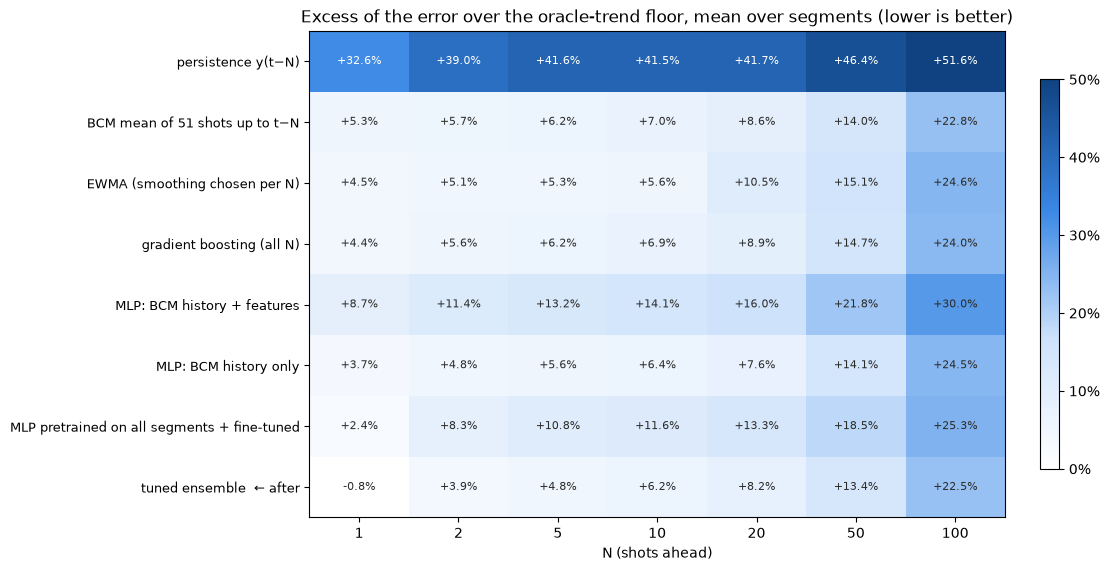

In [7]:
METHODS = list(P[SEGS[0]])
rows = []
for k, d in data.items():
    s, a = segments[k], d["arr"]
    y = s["y"][d["t"]]
    for n in HORIZONS:
        for split in ("val", "test"):
            m = (d["N"] == n) & d[split]
            floor = vm.PC * np.std(y[m] - vm.smooth(y[m]))
            for name in METHODS:
                p = P[k][name][m] * a["ysd"] + a["ym"]
                rows.append({"segment": k, "N": n, "split": split, "method": name, "floor [pC]": floor,
                             **vm.scores_pc(y[m], p)})
scores = pd.DataFrame(rows)
scores["excess over floor"] = scores["std [pC]"] / scores["floor [pC]"] - 1
test = scores[scores["split"] == "test"]
AFTER = scores[scores["split"] == "val"].groupby("method")["excess over floor"].mean().drop(
    ["persistence y(t−N)", "BCM mean of 51 shots up to t−N"]).idxmin()
print(f"after (lowest mean validation excess over the floor): {AFTER}")

excess = test.pivot_table(index="method", columns="N", values="excess over floor", aggfunc="mean").loc[METHODS]
fig, ax = plt.subplots(figsize=(11, 0.5 * len(METHODS) + 1.6), layout="constrained")
im = ax.imshow(excess.clip(upper=0.5), cmap=LinearSegmentedColormap.from_list("seq", ["#ffffff", "#cde2fb", "#3987e5", "#104281"]),
               vmin=0, vmax=0.5, aspect="auto")
for (i, j), v in np.ndenumerate(excess.to_numpy()):
    ax.text(j, i, f"{v:+.1%}", ha="center", va="center", fontsize=8, color="white" if v > 0.3 else INK)
ax.set_xticks(range(len(HORIZONS)), HORIZONS)
ax.set_yticks(range(len(METHODS)), [f"{m}  ← after" if m == AFTER else m for m in METHODS], fontsize=9)
ax.set(xlabel="N (shots ahead)", title="Excess of the error over the oracle-trend floor, mean over segments (lower is better)")
fig.colorbar(im, ax=ax, shrink=0.8, format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.savefig(OUT / "excess_over_floor.png", dpi=130, bbox_inches="tight");

### Before (notebook 10) vs after vs floor, per segment

In [8]:
b = before[before["model"] == "two-step NN: x̂(t) then y(t)"].set_index(["segment", "N"])["std [pC]"]
a = test[test["method"] == AFTER].set_index(["segment", "N"])
mean51 = test[test["method"] == "BCM mean of 51 shots up to t−N"].set_index(["segment", "N"])["std [pC]"]
comp = pd.DataFrame({"before: two-step NN (10)": b, "BCM mean of 51 shots": mean51, f"after: {AFTER}": a["std [pC]"],
                     "oracle-trend floor": a["floor [pC]"]}).dropna(subset=["before: two-step NN (10)"])
comp["after vs before"] = comp[f"after: {AFTER}"] / comp["before: two-step NN (10)"] - 1
comp.style.format({c: "{:.1f}" for c in comp.columns if c != "after vs before"} | {"after vs before": "{:+.1%}"})

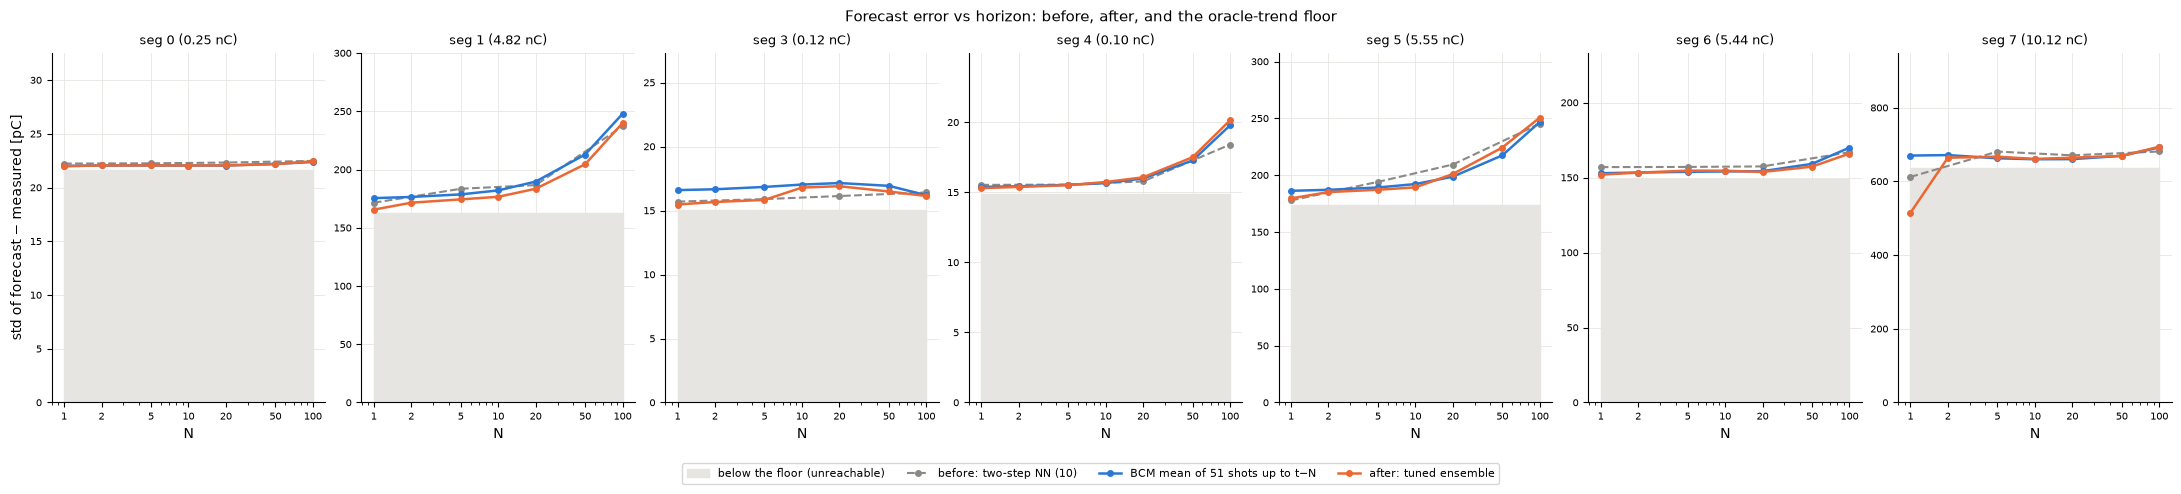

In [9]:
fig, axes = plt.subplots(1, len(SEGS), figsize=(3.1 * len(SEGS), 4.4), layout="constrained")
for ax, k in zip(axes, SEGS):
    g = test[test["segment"] == k]
    fl = g[g["method"] == AFTER].set_index("N")["floor [pC]"]
    ax.fill_between(fl.index, 0, fl.values, color=GRID, label="below the floor (unreachable)")
    bb = before[(before["segment"] == k) & (before["model"] == "two-step NN: x̂(t) then y(t)")]
    ax.plot(bb["N"], bb["std [pC]"], "o--", color=MUTED, lw=1.5, ms=4, label="before: two-step NN (10)")
    for name, color in [("BCM mean of 51 shots up to t−N", "#2a78d6"), (AFTER, "#eb6834")]:
        gg = g[g["method"] == name]
        ax.plot(gg["N"], gg["std [pC]"], "o-", color=color, lw=1.8, ms=4, label=name if name != AFTER else f"after: {AFTER}")
    ax.set(xscale="log", xticks=HORIZONS, xticklabels=HORIZONS, xlabel="N", title=f"seg {k} ({segments[k]['y'][segments[k]['test']].mean():.2f} nC)")
    ax.title.set_fontsize(9)
    ax.tick_params(labelsize=7)
    ax.set_ylim(0, max(g["std [pC]"].max(), bb["std [pC]"].max() if len(bb) else 0) * 1.05)
    vd_plots.style(ax)
axes[0].set_ylabel("std of forecast − measured [pC]")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Forecast error vs horizon: before, after, and the oracle-trend floor", fontsize=11)
fig.savefig(OUT / "before_after_vs_horizon.png", dpi=130, bbox_inches="tight");

### Where does the remaining error sit? (after, slow vs fast part)

slow = 51-shot rolling mean of the difference (trend error, what a forecast can still reduce),
fast = the rest (≈ the floor).

In [10]:
test[test["method"] == AFTER].pivot_table(index="segment", columns="N", values=["slow [pC]", "fast [pC]", "floor [pC]"]).round(1)

fast [pC]                                           floor [pC]         \
N             1      2      5      10     20     50     100        1      2     
segment                                                                         
0            21.9   22.0   21.9   21.9   21.8   21.7   21.8       21.7   21.7   
1           161.8  166.7  168.6  167.9  166.7  166.3  165.2      163.0  163.0   
3            15.2   15.4   15.5   15.5   15.1   15.3   15.2       15.1   15.1   
4            15.1   15.1   15.1   15.1   15.0   15.0   15.0       14.9   14.9   
5           178.9  184.2  184.4  181.1  176.0  174.6  174.7      174.1  174.1   
6           151.3  152.7  153.8  153.3  152.2  150.3  149.7      149.3  149.3   
7           506.0  644.1  642.3  640.0  637.0  636.4  637.7      637.7  637.7   

                ...                      slow [pC]                       \
N          5    ...    20     50     100       1      2      5      10    
segment         ...                                                       
0         21.7  ...   21.7   21.7   21.7       2.7    2.8    3.0    3.2   
1        163.0  ...  163.0  163.0  163.0      33.8   38.4   42.5   51.3   
3         15.1  ...   15.1   15.1   15.1       2.5    2.5    3.0    6.1   
4         14.9  ...   14.9   14.9   14.9       2.6    2.8    3.6    4.3   
5        174.1  ...  174.1  174.1  174.1      18.1   21.4   33.6   53.6   
6        149.3  ...  149.3  149.3  149.3      16.8   17.6   20.0   24.5   
7        637.7  ...  637.7  637.7  637.7      68.5  116.4  137.0  120.8   

                              
N          20     50     100  
segment                       
0          3.6    4.6    5.6  
1         69.7  111.1  168.2  
3          7.0    5.9    5.2  
4          5.5    8.7   13.1  
5         91.7  136.2  175.8  
6         25.5   45.6   68.9  
7        145.9  168.6  242.0  

[7 rows x 21 columns]

### N = 1 check (laser timing)

If the features at `t−1` sometimes contain shot `t`'s own laser reading, the model with features gains much more at
N = 1 than at N = 2 compared with the BCM-only model.

In [11]:
chk = test[test["method"].isin(["MLP: BCM history + features", "MLP: BCM history only"]) & test["N"].isin([1, 2, 5])]
chk = chk.pivot_table(index=["segment", "N"], columns="method", values="std [pC]")
chk["gain of the features"] = 1 - chk["MLP: BCM history + features"] / chk["MLP: BCM history only"]
chk.unstack("N")["gain of the features"].style.format("{:+.1%}").set_caption("error reduction from the features, by horizon")

N,1,2,5
segment,,,
0,-0.5%,+0.1%,+0.0%
1,+0.1%,-2.0%,-2.5%
3,-41.5%,-44.0%,-45.7%
4,+2.0%,+0.7%,+0.9%
5,+2.4%,+0.5%,-0.4%
6,-0.6%,-0.5%,+0.0%
7,+3.9%,+0.6%,-2.4%


## Shot by shot: after vs measured, N = 5, first 200 test shots

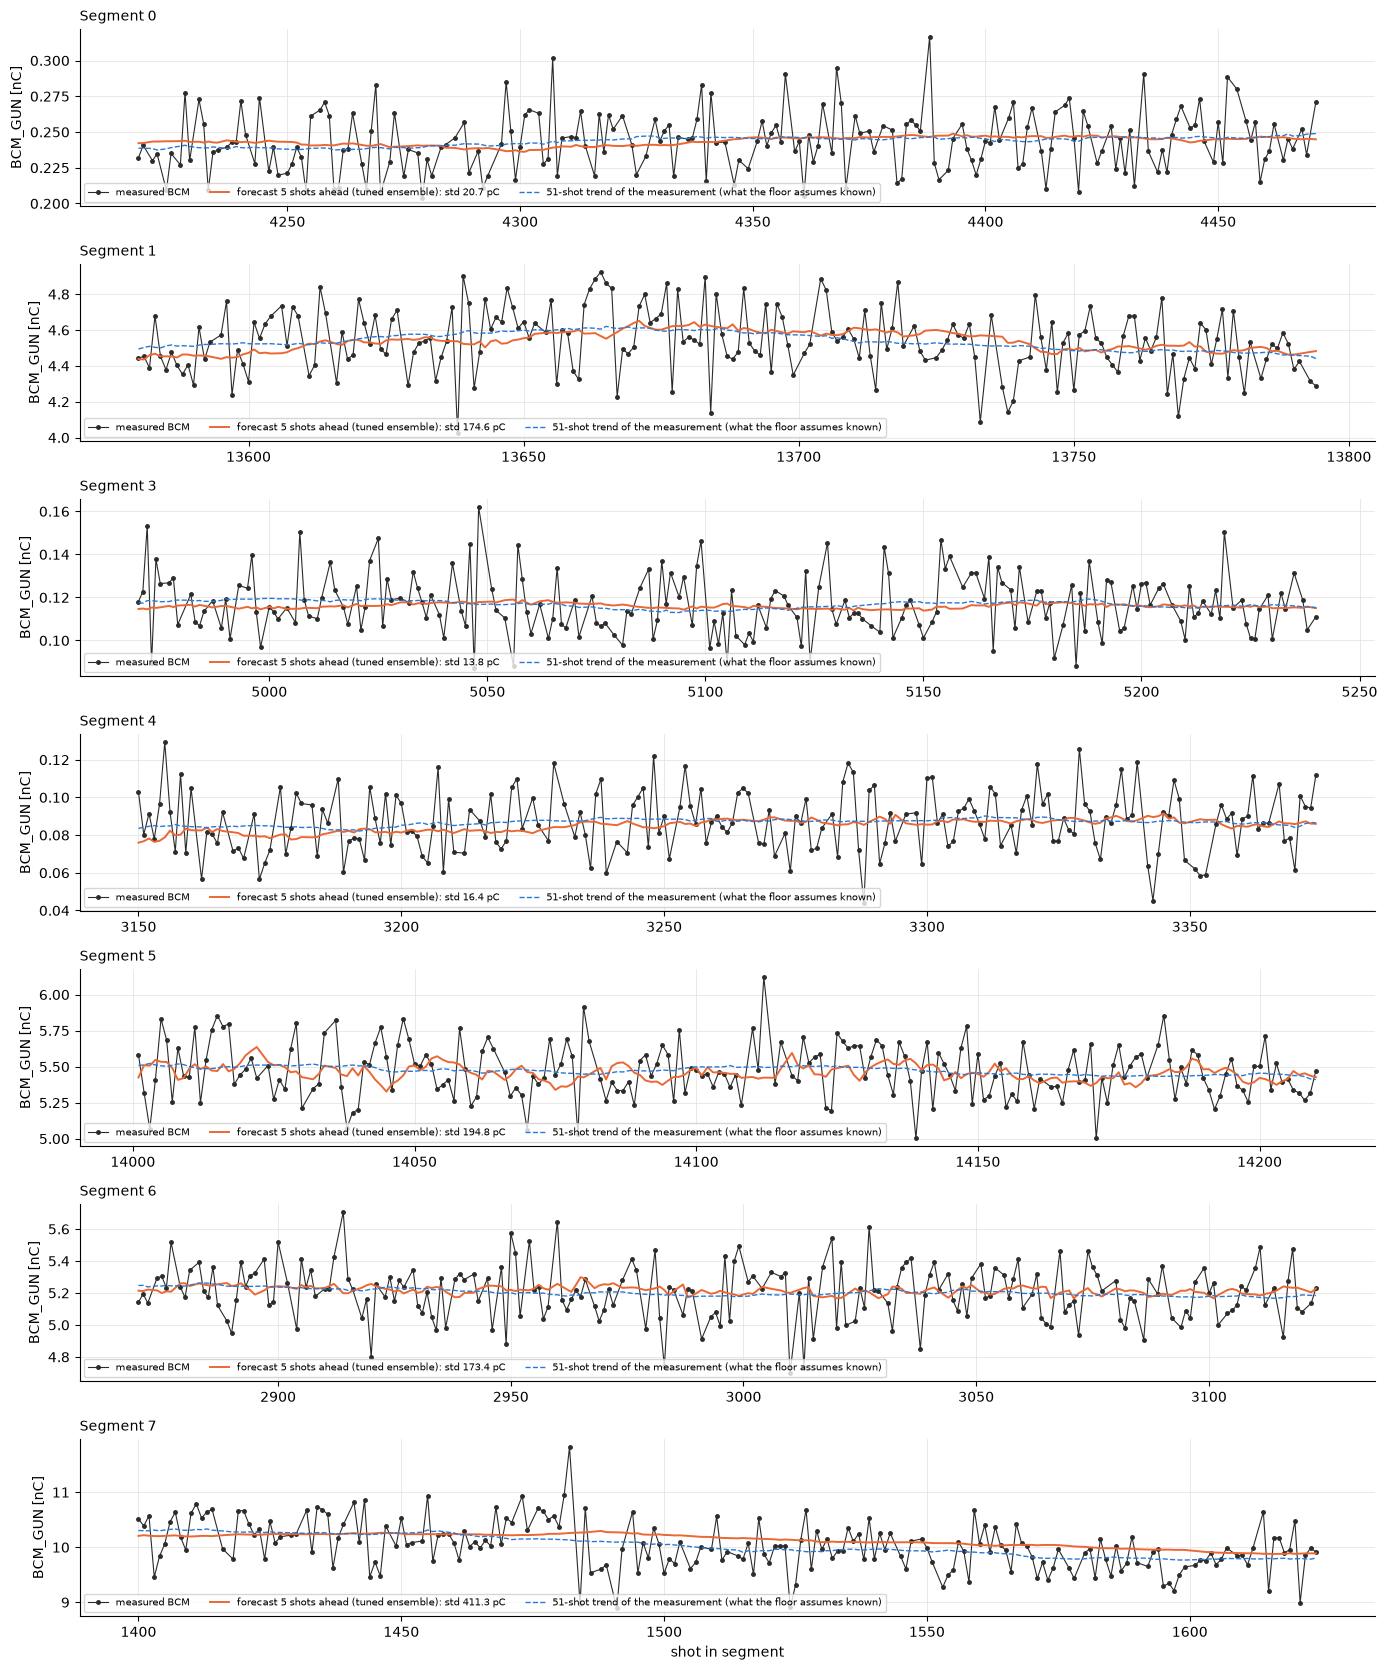

In [12]:
n = 5
fig, axes = plt.subplots(len(SEGS), 1, figsize=(14, 2.4 * len(SEGS)), squeeze=False)
for ax, k in zip(axes[:, 0], SEGS):
    d, a = data[k], data[k]["arr"]
    m = np.flatnonzero((d["N"] == n) & d["test"])[:200]
    y = segments[k]["y"][d["t"][m]]
    p = P[k][AFTER][m] * a["ysd"] + a["ym"]
    ax.plot(d["t"][m], y, "-o", ms=2.5, lw=0.8, color=INK, label="measured BCM")
    ax.plot(d["t"][m], p, lw=1.4, color="#eb6834", label=f"forecast {n} shots ahead ({AFTER}): std {vm.PC * np.std(p - y):.1f} pC")
    ax.plot(d["t"][m], vm.smooth(y), lw=1.0, ls="--", color="#2a78d6", label="51-shot trend of the measurement (what the floor assumes known)")
    ax.set_title(f"Segment {k}", fontsize=10, loc="left")
    ax.set_ylabel("BCM_GUN [nC]")
    ax.legend(fontsize=7, loc="lower left", ncol=3)
    vd_plots.style(ax)
axes[-1, 0].set_xlabel("shot in segment")
fig.tight_layout()
fig.savefig(OUT / "zoom_N5.png", dpi=130, bbox_inches="tight")

In [13]:
frames = []
for k, d in data.items():
    a = d["arr"]
    m = d["test"]
    frames.append(pd.DataFrame({"segment": k, "shot": d["t"][m], "N": d["N"][m], "measured": segments[k]["y"][d["t"][m]],
                                **{name: P[k][name][m] * a["ysd"] + a["ym"] for name in METHODS}}))
pd.concat(frames).to_csv(OUT / "predictions.csv", index=False)
scores.to_csv(OUT / "scores.csv", index=False)
print(f"saved predictions and scores to {OUT}; total {time.time() - t0:.0f} s")

saved predictions and scores to /Users/angilard/Desktop/Fast-Approximate/results/forecast_10_01; total 7804 s
